# Phase 3.2: Nghiên cứu kiến trúc hiện đại Vision Transformer (ViT) & Ứng dụng nhận diện đối tượng trên CIFAR-100

> **Môi trường khuyến nghị:** Google Colab (`Runtime → Change runtime type → T4 / L4 GPU`) hoặc Kaggle (`Settings → Accelerator → GPU T4 / P100`).
> **Framework & Pre-trained Model:** PyTorch + Hugging Face `transformers` (`google/vit-base-patch16-224-in21k`).

---

## 1. Tổng quan các kiến trúc mạng Neural hiện đại trong Thị giác Máy tính

Theo yêu cầu Phase 3.2, dưới đây là so sánh tổng quan 5 họ kiến trúc học sâu hiện đại tiêu biểu trong bài toán nhận diện và xử lý ảnh đối tượng:

| Kiến trúc | Đại diện tiêu biểu | Ý tưởng cốt lõi | Bài toán chính | Ưu điểm nổi bật | Hạn chế chính |
|---|---|---|---|---|---|
| **Modern CNN** | ResNet, EfficientNet, ConvNeXt | Kết nối tắt (*Residual Connections*), tích chập tách chiều sâu (*Depthwise Separable Conv*), chuẩn hóa hiện đại | Phân loại ảnh, Backbone trích xuất đặc trưng | Giả định cục bộ mạnh, hiệu quả cao ngay cả trên tập dữ liệu vừa và nhỏ | Vùng tiếp nhận (*receptive field*) tăng chậm qua từng tầng, khó mô hình hóa phụ thuộc xa toàn cục |
| **ViT (Vision Transformer)** | ViT-B/16, DeiT, DINOv2 | Chia ảnh thành chuỗi các mảnh (*patches*) $16\times16$, áp dụng cơ chế **Multi-Head Self-Attention** thuần túy | Phân loại ảnh, trích xuất đặc trưng nền tảng (*foundation backbone*) | Mô hình hóa ngữ cảnh **toàn cục ngay từ tầng đầu tiên**, mở rộng (*scaling*) và Transfer Learning cực mạnh | Cần pre-training trên dữ liệu lớn (ImageNet-21k) để bù thiếu hụt *inductive bias* |
| **Transformer (Vision)** | DETR, Swin Transformer, Mask2Former | Kết hợp Self-Attention phân cấp (*Shifted Windows*) hoặc Encoder-Decoder với Object Queries | Phát hiện đối tượng (*Object Detection*), phân vùng ảnh (*Segmentation*) | Loại bỏ các bước thủ công (như Anchor Boxes, NMS trong DETR), đa năng | Chi phí tính toán cao với ảnh độ phân giải rất lớn |
| **GAN** | DCGAN, StyleGAN, CycleGAN | Huấn luyện đối kháng giữa **Generator** (sinh ảnh giả) và **Discriminator** (phân biệt thật/giả) | **Sinh ảnh (Image Generation)**, tăng cường dữ liệu, siêu phân giải | Sinh ảnh sắc nét, chân thực cao | Huấn luyện khó ổn định (*mode collapse*), không trực tiếp dùng làm bộ phân loại đối tượng |
| **FPN (Feature Pyramid Network)** | FPN, BiFPN, PANet | Kết hợp đường dẫn *bottom-up* và *top-down* kèm kết nối ngang (*lateral connections*) tạo tháp đặc trưng đa tỷ lệ | Phát hiện đối tượng nhiều kích thước (*Multi-scale Detection / Segmentation*) | Phát hiện rất tốt cả đối tượng rất nhỏ và rất lớn | Là khối *neck* bổ trợ cho backbone, không phải mô hình phân loại độc lập hoàn chỉnh |

### Lý do lựa chọn **Vision Transformer (ViT)** cho bài toán CIFAR-100
1. **Phù hợp trực tiếp với bài toán phân loại 100 lớp đối tượng** (nhiều lớp có hình dáng tương đồng cao như các loài cây, côn trùng, động vật có vú).
2. **Thể hiện rõ bước chuyển đổi mô hình** từ CNN truyền thống (Phase 3.1) sang kiến trúc dựa trên **Self-Attention** hiện đại (Phase 3.2).
3. **Khai thác hiệu quả Pre-trained Model từ Hugging Face** (`google/vit-base-patch16-224-in21k`, pre-trained trên 14 triệu ảnh ImageNet-21k), giải quyết triệt để điểm yếu của CIFAR-100 là số lượng ảnh mỗi lớp rất ít (chỉ 500 ảnh train/lớp).

## 2. Cơ sở lý thuyết chuyên sâu về Vision Transformer (ViT)

Được giới thiệu bởi **Dosovitskiy et al. (Google Research, ICLR 2021)** trong bài báo *"An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale"*, **ViT** xử lý một bức ảnh tương tự như một chuỗi các "từ" (*tokens*) trong Xử lý Ngôn ngữ Tự nhiên (NLP):

### 2.1. Patch Embedding & Positional Encoding
Cho ảnh đầu vào $\mathbf{x} \in \mathbb{R}^{H \times W \times C}$ với $H = W = 224, C = 3$ và kích thước mỗi mảnh (*patch*) $P = 16$:
- Ảnh được chia thành $N = \frac{H \cdot W}{P^2} = \frac{224 \times 224}{16^2} = 14 \times 14 = 196$ patches không chồng lấn.
- Mỗi patch có kích thước $16 \times 16 \times 3 = 768$ giá trị, được chiếu tuyến tính sang vector ẩn chiều $D = 768$ (thực tế cài đặt cực gọn bằng một tầng `Conv2d(3, 768, kernel_size=16, stride=16)`).
- Một vector đặc biệt **`[CLS]` token** ($\mathbf{x}_{\text{class}}$) được gắn vào đầu chuỗi để tổng hợp biểu diễn toàn ảnh, đồng thời cộng thêm **Learnable 1D Positional Embedding** $\mathbf{E}_{\text{pos}} \in \mathbb{R}^{(N+1) \times D}$ để giữ thông tin vị trí không gian:
$$\mathbf{z}_0 = \left[\mathbf{x}_{\text{class}};\; \mathbf{x}_p^1 \mathbf{E};\; \mathbf{x}_p^2 \mathbf{E};\; \dots;\; \mathbf{x}_p^N \mathbf{E}\right] + \mathbf{E}_{\text{pos}} \in \mathbb{R}^{197 \times 768}$$

### 2.2. Khối Transformer Encoder ($L = 12$ tầng trong ViT-Base)
Mỗi tầng Encoder $\ell \in \{1, \dots, 12\}$ gồm **Multi-Head Self-Attention (MSA)** và **MLP** (2 tầng tuyến tính $768 \to 3072 \to 768$ với hàm kích hoạt `GELU`), áp dụng **Pre-LayerNorm** và **Residual Connections**:
$$\mathbf{z}'_\ell = \text{MSA}(\text{LN}(\mathbf{z}_{\ell-1})) + \mathbf{z}_{\ell-1}$$
$$\mathbf{z}_\ell = \text{MLP}(\text{LN}(\mathbf{z}'_\ell)) + \mathbf{z}'_\ell$$

Trong mỗi đầu chú ý (*Attention Head*, $h = 12$, $d_k = 768 / 12 = 64$), ma trận Query ($Q$), Key ($K$), Value ($V$) tính trọng số chú ý toàn cục giữa **mọi cặp patch trên toàn ảnh**:
$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

### 2.3. Đầu phân loại (Classification Head)
Sau tầng cuối cùng, vector biểu diễn của token `[CLS]` ($\mathbf{z}_L^0 \in \mathbb{R}^{768}$) đi qua `LayerNorm` và một tầng tuyến tính `Linear(768, 100)` để dự đoán xác suất cho **100 lớp đối tượng của CIFAR-100**.

### 2.4. So sánh cốt lõi: CNN (Phase 3.1) vs ViT (Phase 3.2)
| Tiêu chí | Basic CNN (Phase 3.1) | Vision Transformer — ViT-B/16 (Phase 3.2) |
|---|---|---|
| Phép toán chính | Tích chập cục bộ ($3 \times 3$) | Tự chú ý toàn cục (*Multi-Head Self-Attention*) |
| Vùng tiếp nhận (*Receptive Field*) | Cục bộ ở tầng đầu, mở rộng dần theo độ sâu | **Toàn cục (100% ảnh)** ngay từ tầng Encoder đầu tiên |
| Giả định quy nạp (*Inductive Bias*) | Mạnh (tính cục bộ + bất biến dịch chuyển) | Yếu hơn → cần Pre-training trên dữ liệu lớn |
| Chiến lược áp dụng | Huấn luyện từ đầu (*from scratch*) trên CIFAR-10 | **Fine-tuning Pre-trained ImageNet-21k** trên CIFAR-100 |

In [1]:
# =============================================================================
# 0. CÀI ĐẶT THƯ VIỆN HUGGING FACE (TƯƠNG THÍCH GOOGLE COLAB & KAGGLE)
# =============================================================================
%pip install -q transformers datasets accelerate scikit-learn seaborn tqdm

In [2]:
# =============================================================================
# 1. IMPORT THƯ VIỆN, KIỂM TRA GPU & CẤU HÌNH THỰC NGHIỆM
# =============================================================================
import contextlib
import json
import os
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import transformers
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    AutoImageProcessor,
    ViTForImageClassification,
    get_cosine_schedule_with_warmup,
)

# Cấu hình biểu đồ
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")

IN_COLAB = "COLAB_GPU" in os.environ or os.path.exists("/content")
IN_KAGGLE = os.path.exists("/kaggle/working")
ENV_NAME = "Google Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "Local")

# Cấu hình tập trung (đặt fast_demo_mode=True nếu muốn chạy kiểm thử nhanh ~2 phút)
CONFIG = {
    "seed": 42,
    "model_name": "google/vit-base-patch16-224-in21k",
    "data_dir": "./data",
    "output_dir": "./outputs/vit_cifar100",
    "val_ratio": 0.1,             # 45,000 train / 5,000 val / 10,000 test
    "epochs": 5,                  # ~12-15 phút trên Colab T4 (đạt ~90-93% Top-1)
    "batch_size": 64,
    "eval_batch_size": 128,
    "lr": 5e-5,                   # Learning rate nhỏ chuẩn Fine-tuning ViT
    "weight_decay": 0.01,
    "warmup_ratio": 0.10,
    "label_smoothing": 0.10,
    "max_grad_norm": 1.0,
    "num_workers": 0 if os.name == "nt" else min(2, os.cpu_count() or 2),
    "fast_demo_mode": False,      # True: 2 epochs trên tập con 10,000 train để test nhanh
}

if CONFIG["fast_demo_mode"]:
    CONFIG["epochs"] = 2

OUTPUT_DIR = Path(CONFIG["output_dir"])
BEST_MODEL_DIR = OUTPUT_DIR / "best_vit_cifar100"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print(f"Môi trường chạy     : {ENV_NAME}")
print(f"PyTorch             : {torch.__version__} | Transformers: {transformers.__version__}")
print(f"Pre-trained Model   : {CONFIG['model_name']}")
print(f"Thiết bị tính toán  : {device} | AMP FP16: {USE_AMP}")
if device.type == "cuda":
    print(f"GPU                 : {torch.cuda.get_device_name(0)}")
    print(f"VRAM                : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Cảnh báo: Không phát hiện GPU! Fine-tuning ViT trên CPU sẽ rất chậm — hãy bật GPU trên Colab/Kaggle.")

Môi trường chạy     : Google Colab
PyTorch             : 2.14.1+cu130 | Transformers: 5.22.1
Pre-trained Model   : google/vit-base-patch16-224-in21k
Thiết bị tính toán  : cuda | AMP FP16: True
GPU                 : Tesla T4
VRAM                : 15.64 GB


## Phần 1: Khám phá bộ dữ liệu CIFAR-100 (100 Fine Classes & 20 Superclasses)

**CIFAR-100** có cùng kích thước ảnh $32 \times 32 \times 3$ và tổng số lượng 60,000 ảnh như CIFAR-10, nhưng độ khó cao hơn rất nhiều:
- **100 lớp chi tiết (*fine classes*)**, nhóm vào **20 siêu lớp (*coarse superclasses*)** (mỗi siêu lớp chứa đúng 5 lớp con).
- Mỗi lớp chỉ có **500 ảnh huấn luyện** (450 ảnh sau khi tách 10% Validation) và **100 ảnh kiểm thử** — ít hơn **10 lần** so với CIFAR-10.
- Nhiều lớp cùng một siêu lớp rất dễ nhầm lẫn ở độ phân giải thấp (ví dụ: `maple_tree` vs `oak_tree`, `boy` vs `girl`, `mouse` vs `shrew`, `bowl` vs `plate`).

→ Đây là bài toán thực tế lý tưởng để chứng minh sức mạnh của **Pre-trained Vision Transformer (ViT)** kết hợp **Transfer Learning**.

Nguồn tải dữ liệu: Hugging Face Datasets (uoft-cs/cifar100)
Tổng số lớp chi tiết (Fine) : 100 lớp | Siêu lớp (Coarse): 20 nhóm
Số lượng mẫu: Train = 45,000 | Validation = 5,000 | Test = 10,000


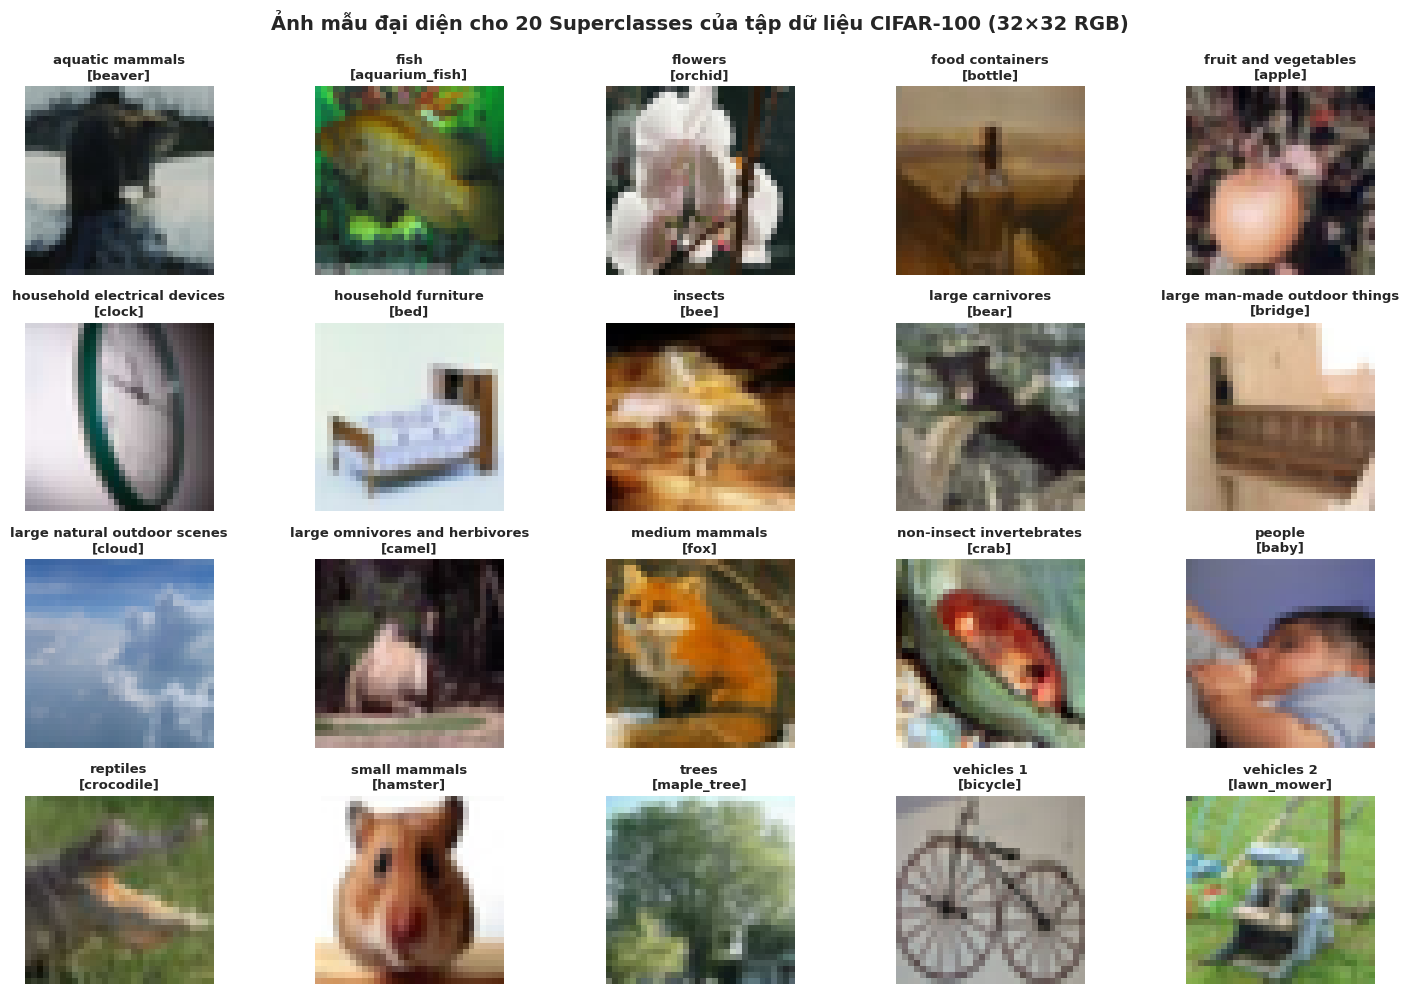

In [3]:
# =============================================================================
# 2. TẢI DỮ LIỆU CIFAR-100, ÁNH XẠ 20 SUPERCLASSES & CHIA STRATIFIED SPLIT
# =============================================================================
class HFCifar100Dataset(Dataset):
    """Tải CIFAR-100 qua Hugging Face Datasets (nhanh & ổn định trên Colab/Kaggle)."""

    def __init__(self, hf_split, label_col: str = "fine_label"):
        # Chuẩn hóa tên lớp 'cra' (typo trên metadata HF uoft-cs/cifar100) thành 'crab'
        self.classes = [
            "crab" if c == "cra" else c for c in hf_split.features[label_col].names
        ]
        self.targets = [int(x) for x in hf_split[label_col]]
        self.data = np.stack([np.asarray(img, dtype=np.uint8) for img in hf_split["img"]], axis=0)

    def __len__(self) -> int:
        return len(self.targets)

    def __getitem__(self, idx: int):
        return Image.fromarray(self.data[idx]), self.targets[idx]


try:
    from datasets import load_dataset

    hf_cifar100 = load_dataset("uoft-cs/cifar100")
    train_raw = HFCifar100Dataset(hf_cifar100["train"], label_col="fine_label")
    test_raw = HFCifar100Dataset(hf_cifar100["test"], label_col="fine_label")
    print("Nguồn tải dữ liệu: Hugging Face Datasets (uoft-cs/cifar100)")
except Exception as err:
    print(f"Không tải được qua Hugging Face ({err}), chuyển sang torchvision.datasets.CIFAR100...")
    train_raw = torchvision.datasets.CIFAR100(root=CONFIG["data_dir"], train=True, download=True)
    test_raw = torchvision.datasets.CIFAR100(root=CONFIG["data_dir"], train=False, download=True)

FINE_CLASSES = train_raw.classes
NUM_CLASSES = len(FINE_CLASSES)

# Ánh xạ chính thức 20 Superclasses -> 100 Fine Classes của CIFAR-100
SUPERCLASS_TO_FINE = {
    "aquatic_mammals": ["beaver", "dolphin", "otter", "seal", "whale"],
    "fish": ["aquarium_fish", "flatfish", "ray", "shark", "trout"],
    "flowers": ["orchid", "poppy", "rose", "sunflower", "tulip"],
    "food_containers": ["bottle", "bowl", "can", "cup", "plate"],
    "fruit_and_vegetables": ["apple", "mushroom", "orange", "pear", "sweet_pepper"],
    "household_electrical_devices": ["clock", "keyboard", "lamp", "telephone", "television"],
    "household_furniture": ["bed", "chair", "couch", "table", "wardrobe"],
    "insects": ["bee", "beetle", "butterfly", "caterpillar", "cockroach"],
    "large_carnivores": ["bear", "leopard", "lion", "tiger", "wolf"],
    "large_man-made_outdoor_things": ["bridge", "castle", "house", "road", "skyscraper"],
    "large_natural_outdoor_scenes": ["cloud", "forest", "mountain", "plain", "sea"],
    "large_omnivores_and_herbivores": ["camel", "cattle", "chimpanzee", "elephant", "kangaroo"],
    "medium_mammals": ["fox", "porcupine", "possum", "raccoon", "skunk"],
    "non-insect_invertebrates": ["crab", "lobster", "snail", "spider", "worm"],
    "people": ["baby", "boy", "girl", "man", "woman"],
    "reptiles": ["crocodile", "dinosaur", "lizard", "snake", "turtle"],
    "small_mammals": ["hamster", "mouse", "rabbit", "shrew", "squirrel"],
    "trees": ["maple_tree", "oak_tree", "palm_tree", "pine_tree", "willow_tree"],
    "vehicles_1": ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],
    "vehicles_2": ["lawn_mower", "rocket", "streetcar", "tank", "tractor"],
}

SUPERCLASSES = list(SUPERCLASS_TO_FINE.keys())
FINE_TO_SUPER = {
    fine: sc for sc, fines in SUPERCLASS_TO_FINE.items() for fine in fines
}
assert set(FINE_TO_SUPER.keys()) == set(FINE_CLASSES), "Lỗi: Danh sách 100 lớp không khớp CIFAR-100!"

FINE_ID_TO_SUPER_ID = np.array([
    SUPERCLASSES.index(FINE_TO_SUPER[cls_name]) for cls_name in FINE_CLASSES
])

# Chia Stratified Train / Val (đúng 450 train & 50 val cho mỗi lớp trong 100 lớp)
train_targets = np.array(train_raw.targets)
sss = StratifiedShuffleSplit(
    n_splits=1, test_size=CONFIG["val_ratio"], random_state=CONFIG["seed"]
)
train_idx, val_idx = next(sss.split(np.zeros(len(train_targets)), train_targets))
test_idx = np.arange(len(test_raw))

if CONFIG["fast_demo_mode"]:
    print("Đang bật FAST_DEMO_MODE: lấy mẫu phân tầng nhỏ để kiểm thử nhanh.")
    sss_demo_tr = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=CONFIG["seed"])
    train_idx = train_idx[next(sss_demo_tr.split(np.zeros(len(train_idx)), train_targets[train_idx]))[0]]
    sss_demo_va = StratifiedShuffleSplit(n_splits=1, train_size=2000, random_state=CONFIG["seed"])
    val_idx = val_idx[next(sss_demo_va.split(np.zeros(len(val_idx)), train_targets[val_idx]))[0]]

print(f"Tổng số lớp chi tiết (Fine) : {NUM_CLASSES} lớp | Siêu lớp (Coarse): {len(SUPERCLASSES)} nhóm")
print(f"Số lượng mẫu: Train = {len(train_idx):,} | Validation = {len(val_idx):,} | Test = {len(test_idx):,}")

# Trực quan hóa 20 ảnh mẫu đại diện cho đủ 20 Superclasses
fig, axes = plt.subplots(4, 5, figsize=(15, 10))
for sc_idx, (sc_name, fine_list) in enumerate(SUPERCLASS_TO_FINE.items()):
    ax = axes[sc_idx // 5, sc_idx % 5]
    chosen_fine = fine_list[0]
    fine_id = FINE_CLASSES.index(chosen_fine)
    sample_pos = int(train_idx[train_targets[train_idx] == fine_id][0])
    ax.imshow(train_raw.data[sample_pos])
    ax.set_title(f"{sc_name.replace('_', ' ')}\n[{chosen_fine}]", fontsize=9.5, fontweight="bold")
    ax.axis("off")

plt.suptitle("Ảnh mẫu đại diện cho 20 Superclasses của tập dữ liệu CIFAR-100 (32×32 RGB)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_cifar100_superclasses_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## Phần 2: Tiền xử lý ảnh & Tải mô hình Pre-trained ViT từ Hugging Face

Ta sử dụng mô hình **`google/vit-base-patch16-224-in21k`** từ Hugging Face Model Hub:
- Được pre-trained trên **ImageNet-21k** (~14 triệu ảnh, 21,843 lớp) ở độ phân giải $224 \times 224$ với kích thước patch $16 \times 16$.
- Phiên bản `-in21k` chưa bị chuyên biệt hóa quá sâu vào 1,000 lớp ImageNet-1k nên là checkpoint tiêu chuẩn tốt nhất cho **Fine-tuning** các bài toán phân loại ảnh mới.
- Các ảnh $32 \times 32$ của CIFAR-100 được phóng lên $224 \times 224$ bằng nội suy **Bicubic**, chuẩn hóa theo đúng `image_mean` và `image_std` của `AutoImageProcessor` từ Hugging Face.

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

Hugging Face ImageProcessor -> size: 224×224, mean: (0.5, 0.5, 0.5), std: (0.5, 0.5, 0.5)


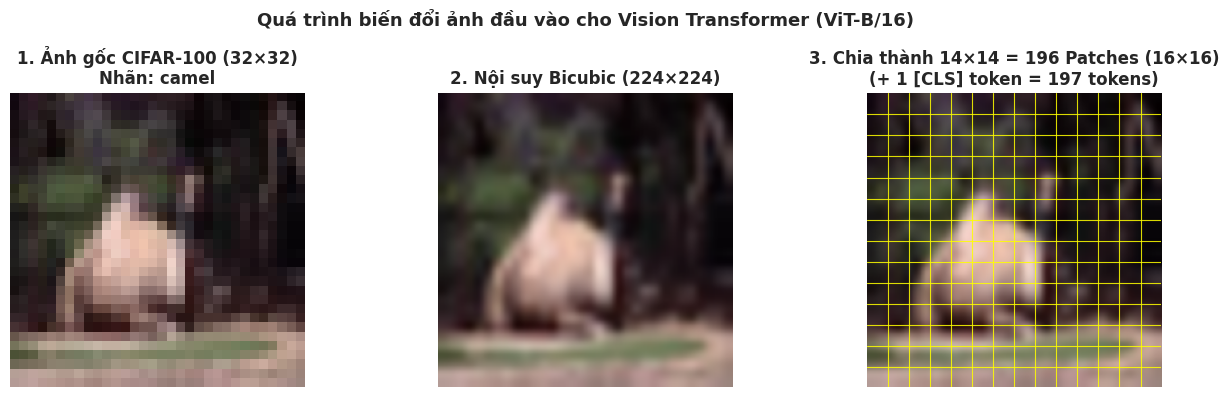

In [4]:
# =============================================================================
# 3. IMAGE PROCESSOR, DATA AUGMENTATION & MINH HỌA LƯỚI 14×14 PATCHES CỦA ViT
# =============================================================================
image_processor = AutoImageProcessor.from_pretrained(CONFIG["model_name"])
IMG_SIZE = image_processor.size.get("height", image_processor.size.get("shortest_edge", 224))
IMG_MEAN = tuple(image_processor.image_mean)
IMG_STD = tuple(image_processor.image_std)
print(f"Hugging Face ImageProcessor -> size: {IMG_SIZE}×{IMG_SIZE}, mean: {IMG_MEAN}, std: {IMG_STD}")


class TransformedSubset(Dataset):
    """Wrapper tách biệt transform giữa tập Train / Validation / Test."""

    def __init__(self, base_dataset: Dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, idx: int):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label


train_transform = T.Compose([
    # Thực hiện ColorJitter & Flip trên ảnh gốc 32x32 trước khi phóng lên 224x224 (nhanh hơn 49× trên CPU)
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    T.RandomResizedCrop(
        IMG_SIZE, scale=(0.8, 1.0), interpolation=T.InterpolationMode.BICUBIC
    ),
    T.ToTensor(),
    T.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

train_ds = TransformedSubset(train_raw, train_idx, transform=train_transform)
val_ds = TransformedSubset(train_raw, val_idx, transform=eval_transform)
test_ds = TransformedSubset(test_raw, test_idx, transform=eval_transform)

train_loader = DataLoader(
    train_ds,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=(device.type == "cuda"),
    persistent_workers=(CONFIG["num_workers"] > 0),
)
val_loader = DataLoader(
    val_ds,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(device.type == "cuda"),
    persistent_workers=(CONFIG["num_workers"] > 0),
)
test_loader = DataLoader(
    test_ds,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(device.type == "cuda"),
    persistent_workers=(CONFIG["num_workers"] > 0),
)

# Minh họa cách ViT chia ảnh 224x224 thành 14x14 = 196 patches 16x16
demo_pil, demo_lbl = train_raw[train_idx[15]]
resized_demo = demo_pil.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(demo_pil)
axes[0].set_title(f"1. Ảnh gốc CIFAR-100 (32×32)\nNhãn: {FINE_CLASSES[demo_lbl]}", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(resized_demo)
axes[1].set_title(f"2. Nội suy Bicubic ({IMG_SIZE}×{IMG_SIZE})", fontweight="bold")
axes[1].axis("off")

axes[2].imshow(resized_demo)
patch_size = 16
for pos in range(patch_size, IMG_SIZE, patch_size):
    axes[2].axhline(pos, color="yellow", linewidth=0.8, alpha=0.85)
    axes[2].axvline(pos, color="yellow", linewidth=0.8, alpha=0.85)
axes[2].set_title("3. Chia thành 14×14 = 196 Patches (16×16)\n(+ 1 [CLS] token = 197 tokens)", fontweight="bold")
axes[2].axis("off")

plt.suptitle("Quá trình biến đổi ảnh đầu vào cho Vision Transformer (ViT-B/16)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_vit_patch_grid.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# =============================================================================
# 4. KHỞI TẠO MÔ HÌNH PRE-TRAINED ViT TỪ HUGGING FACE CHO 100 LỚP CIFAR-100
# =============================================================================
id2label = {i: label for i, label in enumerate(FINE_CLASSES)}
label2id = {label: i for i, label in enumerate(FINE_CLASSES)}

model = ViTForImageClassification.from_pretrained(
    CONFIG["model_name"],
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
head_params = sum(p.numel() for p in model.classifier.parameters())

print("Thông số kiến trúc ViT-Base/16 từ Hugging Face:")
print(f"  - Image size        : {model.config.image_size}×{model.config.image_size}")
print(f"  - Patch size        : {model.config.patch_size}×{model.config.patch_size} ({(model.config.image_size // model.config.patch_size)**2} patches)")
print(f"  - Hidden size (D)   : {model.config.hidden_size}")
print(f"  - Encoder layers (L): {model.config.num_hidden_layers}")
print(f"  - Attention heads   : {model.config.num_attention_heads} (d_k = {model.config.hidden_size // model.config.num_attention_heads})")
print(f"  - MLP intermediate  : {model.config.intermediate_size}")
print(f"  - Tổng số tham số   : {total_params:,} (~{total_params/1e6:.2f}M)")
print(f"  - Tham số Head mới  : {head_params:,} (Linear {model.config.hidden_size} -> {NUM_CLASSES})")

# Kiểm tra nhanh forward pass
with torch.no_grad():
    sample_batch = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)
    sample_out = model(pixel_values=sample_batch)
    print(f"  - Forward check OK  : input {tuple(sample_batch.shape)} -> logits {tuple(sample_out.logits.shape)}")
del sample_batch, sample_out

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Thông số kiến trúc ViT-Base/16 từ Hugging Face:
  - Image size        : 224×224
  - Patch size        : 16×16 (196 patches)
  - Hidden size (D)   : 768
  - Encoder layers (L): 12
  - Attention heads   : 12 (d_k = 64)
  - MLP intermediate  : 3072
  - Tổng số tham số   : 85,875,556 (~85.88M)
  - Tham số Head mới  : 76,900 (Linear 768 -> 100)


  - Forward check OK  : input (2, 3, 224, 224) -> logits (2, 100)


## Phần 3: Chiến lược Fine-tuning ViT trên CIFAR-100

Để khai thác tối đa tri thức pre-trained từ ImageNet-21k mà không làm phá vỡ trọng số ban đầu (*catastrophic forgetting*), ta áp dụng bộ siêu tham số chuẩn cho Fine-tuning Transformer:
- **Optimizer `AdamW` tách nhóm Weight Decay:** Không áp dụng weight decay cho `bias`, `LayerNorm`, `cls_token` và `position_embeddings`.
- **Learning Rate nhỏ (`5e-5`) + Warmup tuyến tính 10% bước đầu + Cosine Decay** (`get_cosine_schedule_with_warmup` từ Hugging Face): giai đoạn warmup giúp tầng `classifier` mới khởi tạo ngẫu nhiên ổn định trước khi cập nhật mạnh backbone.
- **Gradient Clipping (`max_norm = 1.0`)** chống bùng nổ gradient.
- **Label Smoothing (`0.10`)** giảm hiện tượng over-confident trên 100 lớp.
- **Mixed Precision (`AMP FP16`)** giảm ~45% VRAM và tăng tốc ~2 lần trên GPU T4/L4/P100.
- Theo dõi đồng thời **Top-1 Accuracy** và **Top-5 Accuracy** (chuẩn đánh giá phổ biến trên bài toán nhiều lớp như CIFAR-100 & ImageNet).

In [6]:
# =============================================================================
# 5. OPTIMIZER, SCHEDULER & TRAINING / EVALUATION ENGINE (TOP-1 & TOP-5)
# =============================================================================
def get_autocast_ctx(use_amp: bool):
    if not use_amp:
        return contextlib.nullcontext()
    if hasattr(torch, "amp") and hasattr(torch.amp, "autocast"):
        return torch.amp.autocast("cuda", enabled=True)
    return torch.cuda.amp.autocast(enabled=True)


def make_grad_scaler(use_amp: bool):
    if not use_amp:
        return None
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=True)
    return torch.cuda.amp.GradScaler(enabled=True)


def topk_correct_counts(logits: torch.Tensor, targets: torch.Tensor, topk=(1, 5)):
    """Đếm số mẫu dự đoán đúng trong Top-1 và Top-5."""
    max_k = max(topk)
    _, pred = logits.topk(max_k, dim=1, largest=True, sorted=True)
    pred = pred.t()
    correct = pred.eq(targets.view(1, -1).expand_as(pred))
    counts = []
    for k in topk:
        counts.append(correct[:k].reshape(-1).float().sum().item())
    return counts


# Tách nhóm tham số có / không áp dụng weight decay
no_decay_keywords = ("bias", "layernorm", "LayerNorm", "position_embeddings", "cls_token")
optimizer_grouped_parameters = [
    {
        "params": [
            p for n, p in model.named_parameters()
            if not any(kw in n for kw in no_decay_keywords)
        ],
        "weight_decay": CONFIG["weight_decay"],
    },
    {
        "params": [
            p for n, p in model.named_parameters()
            if any(kw in n for kw in no_decay_keywords)
        ],
        "weight_decay": 0.0,
    },
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=CONFIG["lr"])
total_steps = len(train_loader) * CONFIG["epochs"]
warmup_steps = int(total_steps * CONFIG["warmup_ratio"])
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
)
criterion_train = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
criterion_eval = nn.CrossEntropyLoss()
scaler = make_grad_scaler(USE_AMP)

print(f"Tổng số bước tối ưu : {total_steps:,} steps ({len(train_loader)} batches/epoch × {CONFIG['epochs']} epochs)")
print(f"Số bước Warmup      : {warmup_steps:,} steps ({CONFIG['warmup_ratio']*100:.0f}%)")


def train_one_epoch_vit(model, loader, criterion, optimizer, scheduler, scaler, device, use_amp):
    model.train()
    total_loss, top1_hits, top5_hits, total = 0.0, 0.0, 0.0, 0
    step_lrs = []

    pbar = tqdm(loader, desc="  Train", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with get_autocast_ctx(use_amp):
            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)

        if scaler is not None:
            scale_before = scaler.get_scale()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= scale_before:
                scheduler.step()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
            optimizer.step()
            scheduler.step()

        step_lrs.append(optimizer.param_groups[0]["lr"])
        c1, c5 = topk_correct_counts(logits.detach().float(), labels, topk=(1, 5))
        bs = labels.size(0)
        total_loss += loss.item() * bs
        top1_hits += c1
        top5_hits += c5
        total += bs

        pbar.set_postfix(
            loss=f"{total_loss/total:.4f}",
            top1=f"{top1_hits/total*100:.1f}%",
            lr=f"{step_lrs[-1]:.1e}",
        )

    return total_loss / total, top1_hits / total, top5_hits / total, step_lrs


@torch.no_grad()
def evaluate_vit(model, loader, criterion, device, use_amp=False, return_outputs=False):
    model.eval()
    total_loss, top1_hits, top5_hits, total = 0.0, 0.0, 0.0, 0
    all_preds, all_labels, all_probs = [], [], []

    for images, labels in tqdm(loader, desc="  Eval ", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with get_autocast_ctx(use_amp):
            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)

        logits_fp32 = logits.float()
        c1, c5 = topk_correct_counts(logits_fp32, labels, topk=(1, 5))
        bs = labels.size(0)
        total_loss += loss.item() * bs
        top1_hits += c1
        top5_hits += c5
        total += bs

        if return_outputs:
            probs = F.softmax(logits_fp32, dim=1)
            all_preds.append(probs.argmax(dim=1).cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    metrics = (total_loss / total, top1_hits / total, top5_hits / total)
    if return_outputs:
        return (
            *metrics,
            np.concatenate(all_preds),
            np.concatenate(all_labels),
            np.concatenate(all_probs),
        )
    return metrics

Tổng số bước tối ưu : 3,520 steps (704 batches/epoch × 5 epochs)
Số bước Warmup      : 352 steps (10%)


In [7]:
# =============================================================================
# 6. CHẠY FINE-TUNING ViT-B/16 TRÊN CIFAR-100 & LƯU BEST CHECKPOINT HUGGING FACE
# =============================================================================
history = {
    "train_loss": [],
    "train_top1": [],
    "train_top5": [],
    "val_loss": [],
    "val_top1": [],
    "val_top5": [],
    "step_lrs": [],
}

best_val_top1 = 0.0
best_epoch = 0
train_start_time = time.time()

print("=" * 84)
print(f"Bắt đầu Fine-tuning {CONFIG['model_name']} trên CIFAR-100 ({CONFIG['epochs']} epochs)")
print("=" * 84)

for epoch in range(1, CONFIG["epochs"] + 1):
    ep_t0 = time.time()
    tr_loss, tr_top1, tr_top5, ep_lrs = train_one_epoch_vit(
        model, train_loader, criterion_train, optimizer, scheduler, scaler, device, USE_AMP
    )
    va_loss, va_top1, va_top5 = evaluate_vit(
        model, val_loader, criterion_eval, device, USE_AMP
    )

    history["train_loss"].append(tr_loss)
    history["train_top1"].append(tr_top1)
    history["train_top5"].append(tr_top5)
    history["val_loss"].append(va_loss)
    history["val_top1"].append(va_top1)
    history["val_top5"].append(va_top5)
    history["step_lrs"].extend(ep_lrs)

    marker = ""
    if va_top1 > best_val_top1:
        best_val_top1 = va_top1
        best_epoch = epoch
        model.save_pretrained(BEST_MODEL_DIR)
        image_processor.save_pretrained(BEST_MODEL_DIR)
        marker = "  ★ Saved Best (HF format)"

    ep_sec = time.time() - ep_t0
    print(
        f"Epoch {epoch:02d}/{CONFIG['epochs']:02d} | "
        f"Train Loss: {tr_loss:.4f} Top1: {tr_top1*100:5.2f}% | "
        f"Val Loss: {va_loss:.4f} Top1: {va_top1*100:5.2f}% Top5: {va_top5*100:5.2f}% | "
        f"{ep_sec:.1f}s{marker}"
    )

total_train_time = time.time() - train_start_time
print("-" * 84)
print(
    f"Hoàn tất Fine-tuning trong {total_train_time/60:.2f} phút | "
    f"Best Val Top-1: {best_val_top1*100:.2f}% (Epoch {best_epoch})"
)
print(f"Checkpoint Hugging Face tốt nhất được lưu tại: {BEST_MODEL_DIR}")

Bắt đầu Fine-tuning google/vit-base-patch16-224-in21k trên CIFAR-100 (5 epochs)


  Train:   0%|          | 0/704 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 01/05 | Train Loss: 3.3634 Top1: 62.14% | Val Loss: 1.5499 Top1: 87.88% Top5: 98.34% | 437.1s  ★ Saved Best (HF format)


  Train:   0%|          | 0/704 [00:00<?, ?it/s]

... (11 outputs left out)

  Train:   0%|          | 0/704 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 05/05 | Train Loss: 0.8418 Top1: 98.37% | Val Loss: 0.3939 Top1: 92.48% Top5: 99.02% | 444.5s  ★ Saved Best (HF format)
------------------------------------------------------------------------------------
Hoàn tất Fine-tuning trong 36.88 phút | Best Val Top-1: 92.48% (Epoch 5)
Checkpoint Hugging Face tốt nhất được lưu tại: outputs/vit_cifar100/best_vit_cifar100


## Phần 4: Đánh giá chi tiết trên tập Test CIFAR-100 (10,000 ảnh)

Ta nạp lại checkpoint tốt nhất bằng `ViTForImageClassification.from_pretrained(BEST_MODEL_DIR)` và đánh giá toàn diện ở cả 2 cấp độ:
1. **Cấp độ 100 Fine Classes:** Test Top-1 Accuracy, Test Top-5 Accuracy, Macro Precision / Recall / F1, biểu đồ Top-10 lớp tốt nhất & Top-10 lớp khó nhất, Top-15 cặp lớp dễ nhầm lẫn nhất.
2. **Cấp độ 20 Superclasses:** Độ chính xác theo siêu lớp (*Superclass Accuracy*) và **Confusion Matrix 20×20** giúp quan sát trực quan sự nhầm lẫn giữa các nhóm đối tượng lớn (thay vì ma trận 100×100 quá dày đặc).

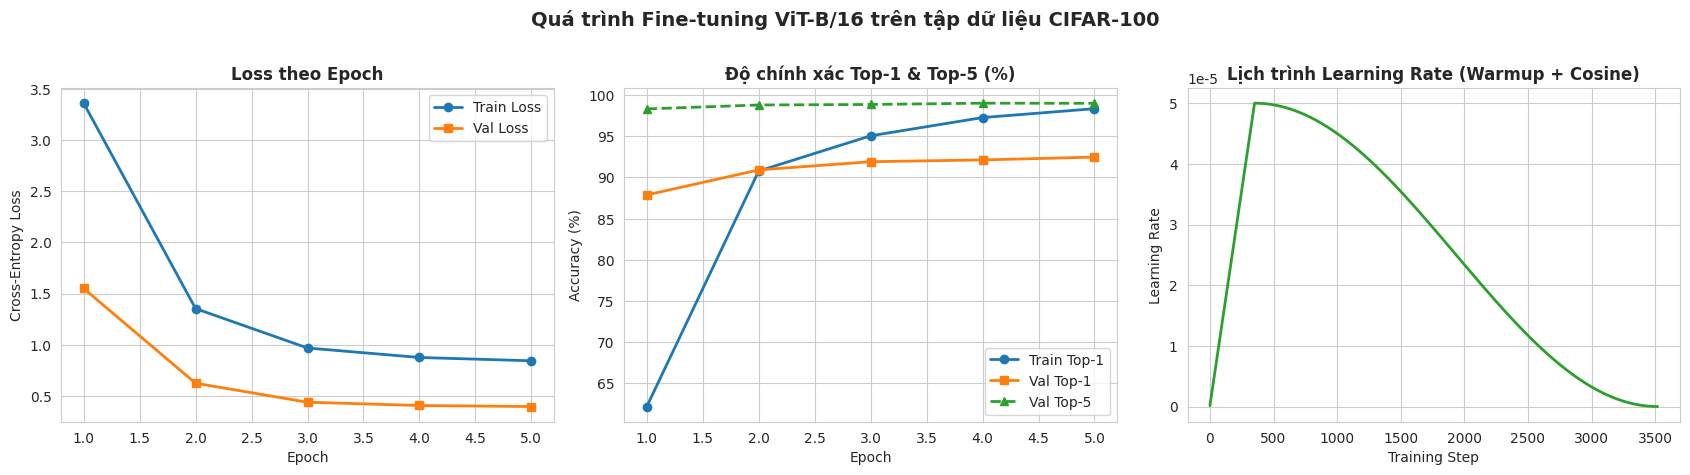

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

KẾT QUẢ ĐÁNH GIÁ ViT-B/16 TRÊN TẬP TEST CIFAR-100 (10,000 ảnh)
  Test Loss                : 0.4038
  Test Top-1 Accuracy (100): 92.22%
  Test Top-5 Accuracy (100): 99.12%
  Macro Precision          : 92.30%
  Macro Recall             : 92.22%
  Macro F1-score           : 92.23%
  Superclass Accuracy (20) : 96.50%


In [8]:
# =============================================================================
# 7. LEARNING CURVES & ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST CIFAR-100 (10,000 ẢNH)
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ep_axis = range(1, len(history["train_loss"]) + 1)

axes[0].plot(ep_axis, history["train_loss"], marker="o", label="Train Loss", linewidth=2)
axes[0].plot(ep_axis, history["val_loss"], marker="s", label="Val Loss", linewidth=2)
axes[0].set_title("Loss theo Epoch", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(ep_axis, [x * 100 for x in history["train_top1"]], marker="o", label="Train Top-1", linewidth=2)
axes[1].plot(ep_axis, [x * 100 for x in history["val_top1"]], marker="s", label="Val Top-1", linewidth=2)
axes[1].plot(ep_axis, [x * 100 for x in history["val_top5"]], marker="^", linestyle="--", label="Val Top-5", linewidth=2)
axes[1].set_title("Độ chính xác Top-1 & Top-5 (%)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

axes[2].plot(history["step_lrs"], color="#2ca02c", linewidth=2)
axes[2].set_title("Lịch trình Learning Rate (Warmup + Cosine)", fontweight="bold")
axes[2].set_xlabel("Training Step")
axes[2].set_ylabel("Learning Rate")

plt.suptitle("Quá trình Fine-tuning ViT-B/16 trên tập dữ liệu CIFAR-100", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_vit_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Nạp lại model tốt nhất theo chuẩn Hugging Face và đánh giá tập Test
best_model = ViTForImageClassification.from_pretrained(BEST_MODEL_DIR).to(device)
test_loss, test_top1, test_top5, y_pred, y_true, y_probs = evaluate_vit(
    best_model, test_loader, criterion_eval, device, USE_AMP, return_outputs=True
)

macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
y_true_super = FINE_ID_TO_SUPER_ID[y_true]
y_pred_super = FINE_ID_TO_SUPER_ID[y_pred]
superclass_acc = accuracy_score(y_true_super, y_pred_super)

print("=" * 70)
print("KẾT QUẢ ĐÁNH GIÁ ViT-B/16 TRÊN TẬP TEST CIFAR-100 (10,000 ảnh)")
print("=" * 70)
print(f"  Test Loss                : {test_loss:.4f}")
print(f"  Test Top-1 Accuracy (100): {test_top1 * 100:.2f}%")
print(f"  Test Top-5 Accuracy (100): {test_top5 * 100:.2f}%")
print(f"  Macro Precision          : {macro_prec * 100:.2f}%")
print(f"  Macro Recall             : {macro_rec * 100:.2f}%")
print(f"  Macro F1-score           : {macro_f1 * 100:.2f}%")
print(f"  Superclass Accuracy (20) : {superclass_acc * 100:.2f}%")
print("=" * 70)

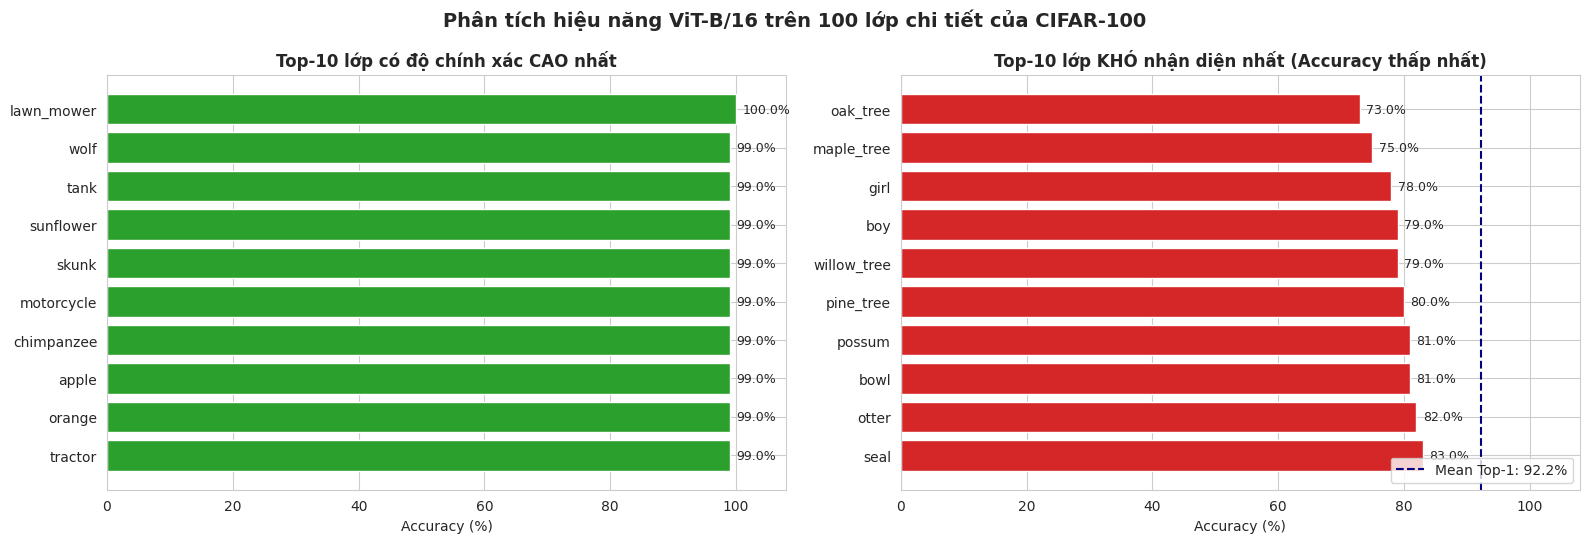

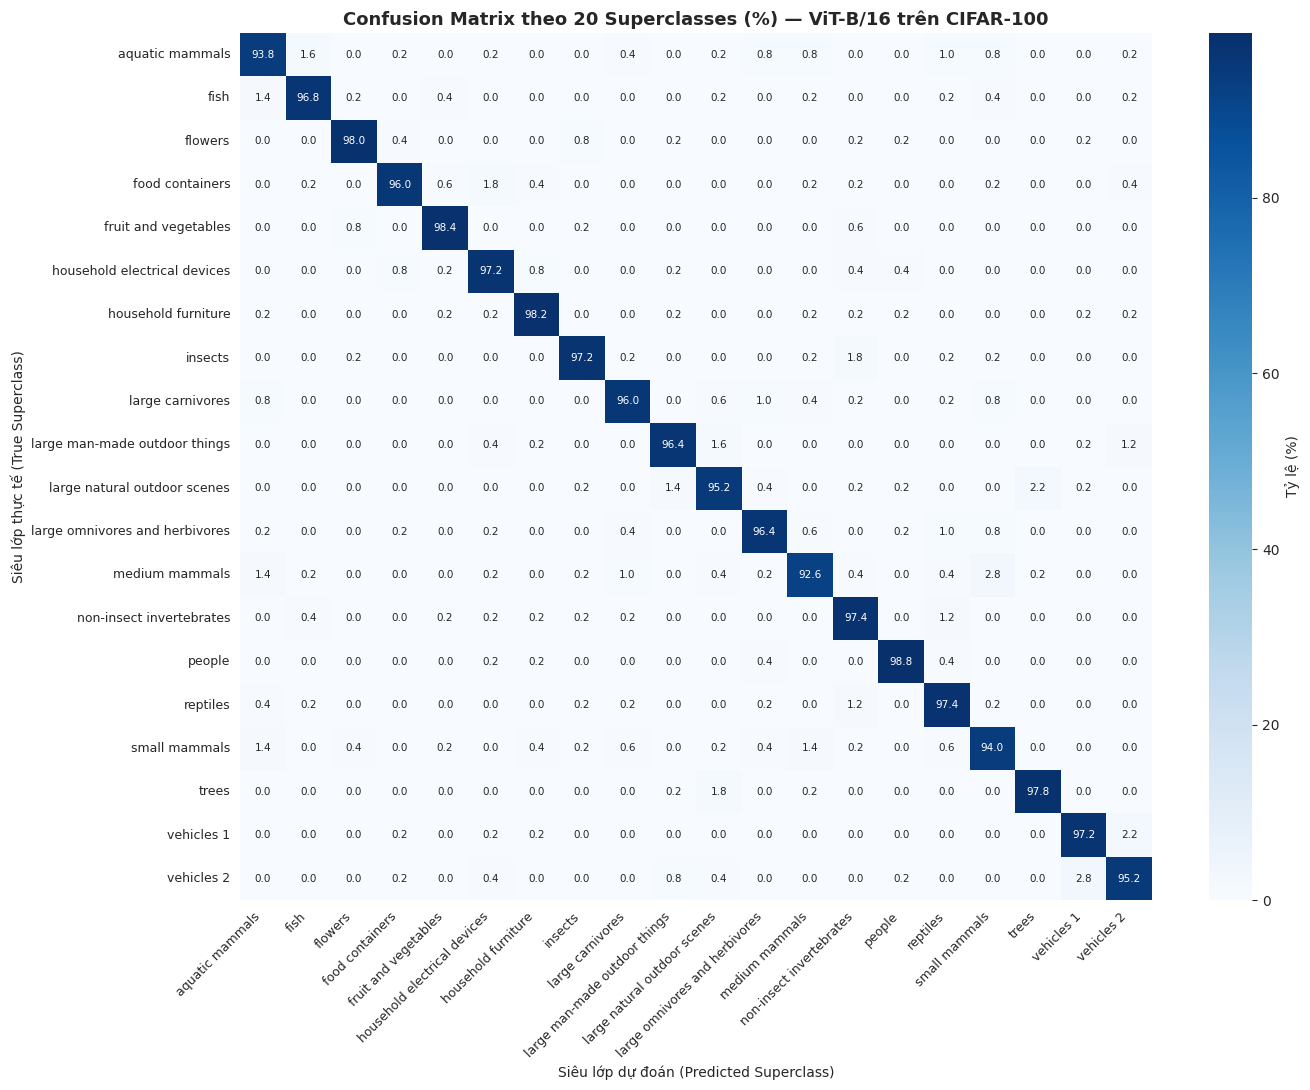

Tổng số ảnh dự đoán sai: 778/10,000 | Trong đó nhầm giữa các lớp CÙNG Superclass: 428 (55.0%)

Top 15 cặp lớp bị nhầm lẫn nhiều nhất (Nhãn thật -> Dự đoán nhầm):
  - oak_tree         -> maple_tree      : 21 ảnh  [Cùng Superclass]
  - maple_tree       -> oak_tree        : 19 ảnh  [Cùng Superclass]
  - seal             -> otter           : 10 ảnh  [Cùng Superclass]
  - bowl             -> plate           :  9 ảnh  [Cùng Superclass]
  - girl             -> baby            :  9 ảnh  [Cùng Superclass]
  - man              -> boy             :  9 ảnh  [Cùng Superclass]
  - pine_tree        -> oak_tree        :  9 ảnh  [Cùng Superclass]
  - willow_tree      -> maple_tree      :  9 ảnh  [Cùng Superclass]
  - baby             -> boy             :  8 ảnh  [Cùng Superclass]
  - boy              -> man             :  8 ảnh  [Cùng Superclass]
  - mouse            -> shrew           :  8 ảnh  [Cùng Superclass]
  - otter            -> seal            :  8 ảnh  [Cùng Superclass]
  - woman            -

In [9]:
# =============================================================================
# 8. PHÂN TÍCH THEO LỚP: TOP-10 DỄ / KHÓ, SUPERCLASS CONFUSION MATRIX & LỖI NHẦM
# =============================================================================
cm_fine = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
per_class_acc = np.diag(cm_fine) / np.maximum(cm_fine.sum(axis=1), 1) * 100.0

sorted_ids = np.argsort(per_class_acc)
hardest_10 = sorted_ids[:10]
easiest_10 = sorted_ids[-10:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].barh([FINE_CLASSES[i] for i in easiest_10][::-1], per_class_acc[easiest_10][::-1], color="#2ca02c")
axes[0].set_xlim(0, 108)
axes[0].set_title("Top-10 lớp có độ chính xác CAO nhất", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Accuracy (%)")
for idx_bar, val in enumerate(per_class_acc[easiest_10][::-1]):
    axes[0].text(val + 1, idx_bar, f"{val:.1f}%", va="center", fontsize=9)

axes[1].barh([FINE_CLASSES[i] for i in hardest_10][::-1], per_class_acc[hardest_10][::-1], color="#d62728")
axes[1].set_xlim(0, 108)
axes[1].axvline(test_top1 * 100, color="navy", linestyle="--", label=f"Mean Top-1: {test_top1*100:.1f}%")
axes[1].set_title("Top-10 lớp KHÓ nhận diện nhất (Accuracy thấp nhất)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Accuracy (%)")
axes[1].legend(loc="lower right")
for idx_bar, val in enumerate(per_class_acc[hardest_10][::-1]):
    axes[1].text(val + 1, idx_bar, f"{val:.1f}%", va="center", fontsize=9)

plt.suptitle("Phân tích hiệu năng ViT-B/16 trên 100 lớp chi tiết của CIFAR-100", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_top_bottom_classes.png", dpi=150, bbox_inches="tight")
plt.show()

# Confusion Matrix 20x20 theo 20 Superclasses
cm_super = confusion_matrix(y_true_super, y_pred_super, labels=range(len(SUPERCLASSES)))
cm_super_norm = cm_super.astype(float) / np.maximum(cm_super.sum(axis=1, keepdims=True), 1) * 100.0
short_sc_names = [s.replace("_", " ") for s in SUPERCLASSES]

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm_super_norm,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=short_sc_names,
    yticklabels=short_sc_names,
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Tỷ lệ (%)"},
)
plt.title("Confusion Matrix theo 20 Superclasses (%) — ViT-B/16 trên CIFAR-100", fontsize=13, fontweight="bold")
plt.xlabel("Siêu lớp dự đoán (Predicted Superclass)")
plt.ylabel("Siêu lớp thực tế (True Superclass)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_superclass_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Thống kê Top-15 cặp lớp hay bị nhầm lẫn nhất & tỷ lệ lỗi thuộc CÙNG Superclass
confused_pairs = []
same_super_errors = 0
total_errors = int((y_pred != y_true).sum())
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm_fine[i, j] > 0:
            cnt = int(cm_fine[i, j])
            is_same_sc = bool(FINE_ID_TO_SUPER_ID[i] == FINE_ID_TO_SUPER_ID[j])
            if is_same_sc:
                same_super_errors += cnt
            confused_pairs.append((FINE_CLASSES[i], FINE_CLASSES[j], cnt, is_same_sc))

confused_pairs.sort(key=lambda x: x[2], reverse=True)
print(
    f"Tổng số ảnh dự đoán sai: {total_errors:,}/10,000 | "
    f"Trong đó nhầm giữa các lớp CÙNG Superclass: {same_super_errors:,} "
    f"({same_super_errors / max(total_errors, 1) * 100:.1f}%)"
)
print("\nTop 15 cặp lớp bị nhầm lẫn nhiều nhất (Nhãn thật -> Dự đoán nhầm):")
for t_cls, p_cls, cnt, same_sc in confused_pairs[:15]:
    tag = "[Cùng Superclass]" if same_sc else "[Khác Superclass]"
    print(f"  - {t_cls:16s} -> {p_cls:16s}: {cnt:2d} ảnh  {tag}")

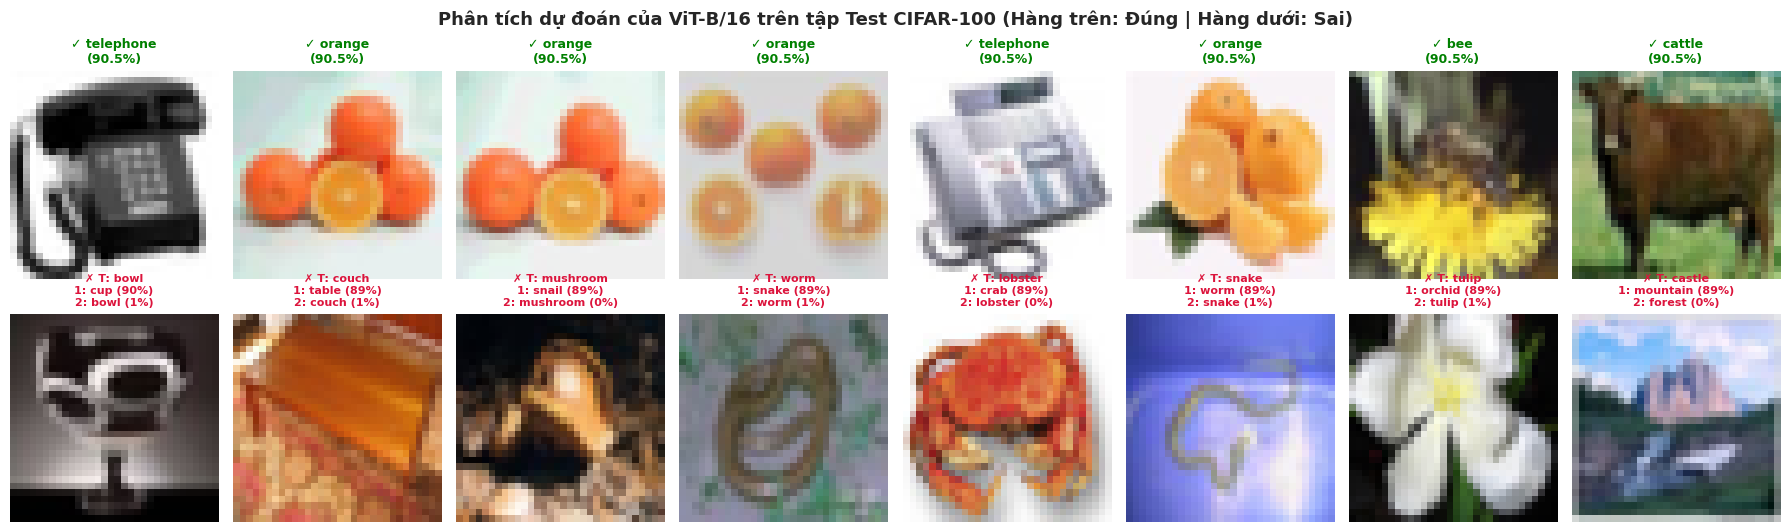

In [10]:
# =============================================================================
# 9. TRỰC QUAN HÓA CÁC MẪU DỰ ĐOÁN ĐÚNG & SAI KÈM TOP-3 XÁC SUẤT
# =============================================================================
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

top_correct = correct_idx[np.argsort(y_probs[correct_idx, y_pred[correct_idx]])[::-1][:8]]
top_wrong = wrong_idx[np.argsort(y_probs[wrong_idx, y_pred[wrong_idx]])[::-1][:8]]

fig, axes = plt.subplots(2, 8, figsize=(18, 5.5))
for col, idx in enumerate(top_correct):
    axes[0, col].imshow(test_raw.data[idx])
    conf = y_probs[idx, y_pred[idx]] * 100
    axes[0, col].set_title(
        f"✓ {FINE_CLASSES[y_pred[idx]]}\n({conf:.1f}%)",
        color="green",
        fontsize=9,
        fontweight="bold",
    )
    axes[0, col].axis("off")

for col, idx in enumerate(top_wrong):
    axes[1, col].imshow(test_raw.data[idx])
    top2 = np.argsort(y_probs[idx])[::-1][:2]
    p1_name, p1_prob = FINE_CLASSES[top2[0]], y_probs[idx, top2[0]] * 100
    p2_name, p2_prob = FINE_CLASSES[top2[1]], y_probs[idx, top2[1]] * 100
    axes[1, col].set_title(
        f"✗ T: {FINE_CLASSES[y_true[idx]]}\n1: {p1_name} ({p1_prob:.0f}%)\n2: {p2_name} ({p2_prob:.0f}%)",
        color="crimson",
        fontsize=8,
        fontweight="bold",
    )
    axes[1, col].axis("off")

plt.suptitle("Phân tích dự đoán của ViT-B/16 trên tập Test CIFAR-100 (Hàng trên: Đúng | Hàng dưới: Sai)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_vit_predictions_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

## Phần 5: Giải thích mô hình (Explainability) — Trực quan hóa Attention Rollout của ViT

Một ưu điểm lớn của Vision Transformer là khả năng **giải thích trực quan vùng ảnh mà mô hình đang chú ý** thông qua kỹ thuật **Attention Rollout** (*Abnar & Zuidema, ACL 2020*):
- Ở mỗi tầng Encoder $\ell \in \{1, \dots, 12\}$, ta lấy trung bình ma trận Attention qua $12$ heads: $\bar{A}^{(\ell)} \in \mathbb{R}^{197 \times 197}$.
- Cộng ma trận đơn vị $I$ để tính đến kết nối tắt (*Residual Connection*) và chuẩn hóa theo từng hàng:
$$\hat{A}^{(\ell)} = \text{row\_norm}\!\left(0.5\,\bar{A}^{(\ell)} + 0.5\,I\right)$$
- Nhân tích lũy qua toàn bộ 12 tầng: $R = \hat{A}^{(12)} \hat{A}^{(11)} \cdots \hat{A}^{(1)}$.
- Hàng đầu tiên $R_{0, 1:197}$ biểu thị mức độ đóng góp của từng mảnh ảnh ($14 \times 14$) vào `[CLS]` token dùng để phân loại đối tượng!

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

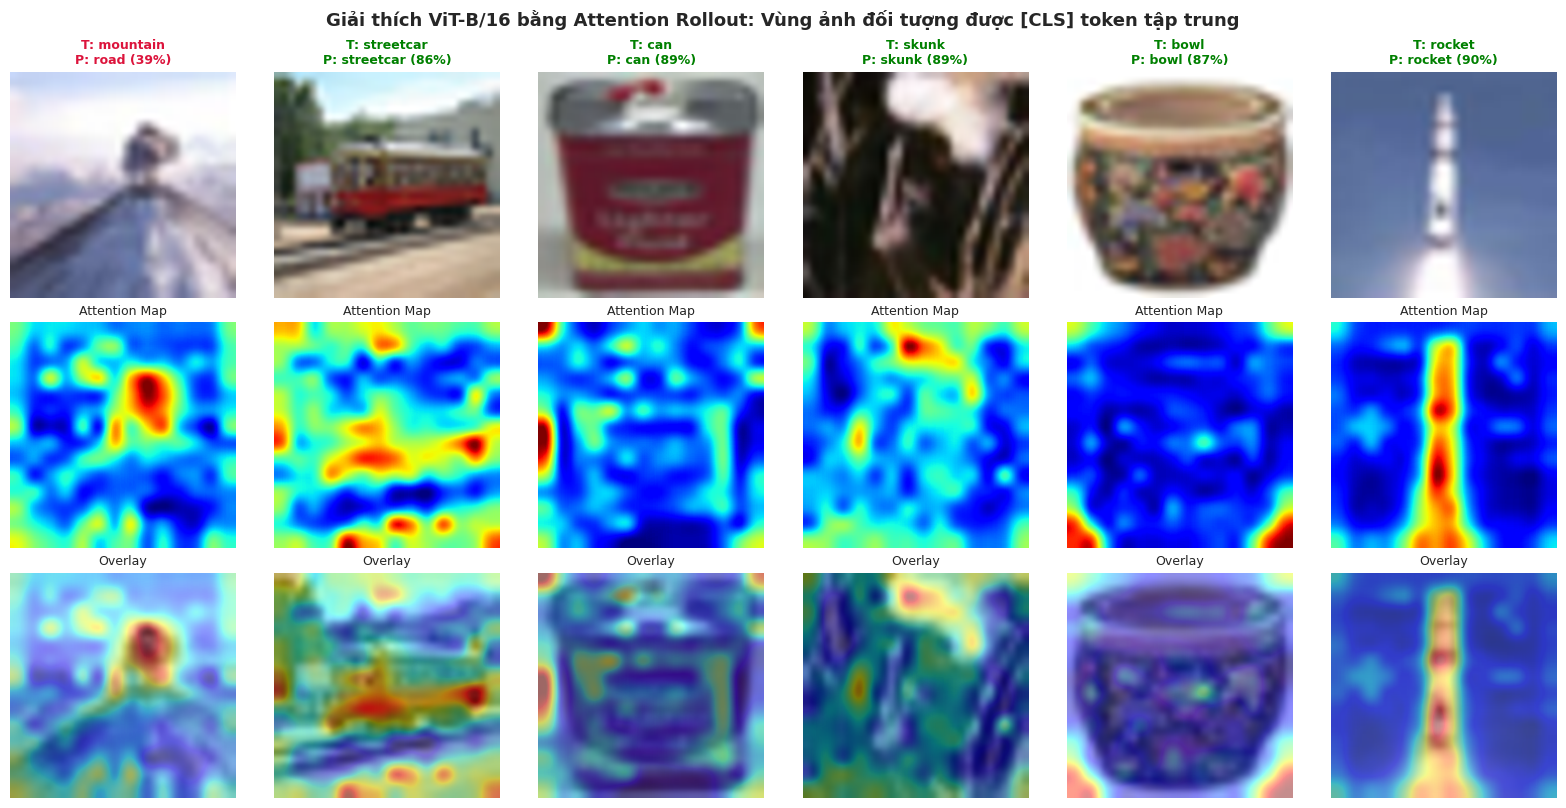

In [11]:
# =============================================================================
# 10. TRỰC QUAN HÓA ATTENTION ROLLOUT CỦA ViT-B/16
# =============================================================================
# Nạp bản sao với attn_implementation="eager" để đảm bảo trả về đầy đủ ma trận attention
# (mặc định PyTorch 2.x SDPA không xuất tensor attention).
try:
    attn_model = ViTForImageClassification.from_pretrained(
        BEST_MODEL_DIR, attn_implementation="eager"
    ).to(device)
except TypeError:
    attn_model = ViTForImageClassification.from_pretrained(BEST_MODEL_DIR).to(device)
attn_model.eval()


@torch.no_grad()
def compute_attention_rollout(model_eager, pil_image: Image.Image, discard_ratio: float = 0.0):
    """Tính bản đồ Attention Rollout (224x224) và nhãn dự đoán cho 1 ảnh PIL."""
    x = eval_transform(pil_image).unsqueeze(0).to(device)
    outputs = model_eager(pixel_values=x, output_attentions=True)
    probs = F.softmax(outputs.logits.float(), dim=1).squeeze(0).cpu().numpy()
    pred_id = int(probs.argmax())
    pred_conf = float(probs[pred_id])

    attentions = outputs.attentions  # tuple 12 tensors: (1, num_heads, 197, 197)
    num_tokens = attentions[0].size(-1)
    joint_att = torch.eye(num_tokens, device=device)

    for att in attentions:
        # Trung bình qua 12 attention heads -> (197, 197)
        att_heads_fused = att.squeeze(0).mean(dim=0)
        if discard_ratio > 0:
            flat = att_heads_fused.view(-1)
            k = int(flat.numel() * discard_ratio)
            if k > 0:
                _, low_idx = flat.topk(k, largest=False)
                flat[low_idx] = 0.0
        # Cộng residual connection và chuẩn hóa theo hàng
        aug_att = 0.5 * att_heads_fused + 0.5 * torch.eye(num_tokens, device=device)
        aug_att = aug_att / aug_att.sum(dim=-1, keepdim=True)
        joint_att = torch.matmul(aug_att, joint_att)

    # Lấy mức độ chú ý từ [CLS] token (hàng 0) tới 196 image patches (cột 1:)
    cls_to_patches = joint_att[0, 1:]
    grid_size = int(np.sqrt(cls_to_patches.numel()))
    mask = cls_to_patches.reshape(grid_size, grid_size).cpu().numpy()
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)

    mask_pil = Image.fromarray(np.uint8(mask * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    mask_224 = np.asarray(mask_pil, dtype=np.float32) / 255.0
    return mask_224, pred_id, pred_conf


# Chọn 6 ảnh thuộc 6 lớp khác nhau từ tập Test để minh họa Attention Rollout
sample_ids = [0, 12, 25, 48, 77, 105]
fig, axes = plt.subplots(3, len(sample_ids), figsize=(16, 8.2))

for col, s_idx in enumerate(sample_ids):
    pil_img, true_id = test_raw[s_idx]
    img_224 = np.asarray(pil_img.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC))
    rollout_map, pred_id, pred_conf = compute_attention_rollout(attn_model, pil_img, discard_ratio=0.1)

    axes[0, col].imshow(img_224)
    color_title = "green" if pred_id == true_id else "crimson"
    axes[0, col].set_title(
        f"T: {FINE_CLASSES[true_id]}\nP: {FINE_CLASSES[pred_id]} ({pred_conf*100:.0f}%)",
        fontsize=9,
        fontweight="bold",
        color=color_title,
    )
    axes[0, col].axis("off")

    axes[1, col].imshow(rollout_map, cmap="jet")
    axes[1, col].set_title("Attention Map", fontsize=9)
    axes[1, col].axis("off")

    axes[2, col].imshow(img_224)
    axes[2, col].imshow(rollout_map, cmap="jet", alpha=0.45)
    axes[2, col].set_title("Overlay", fontsize=9)
    axes[2, col].axis("off")

plt.suptitle("Giải thích ViT-B/16 bằng Attention Rollout: Vùng ảnh đối tượng được [CLS] token tập trung", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_vit_attention_rollout.png", dpi=150, bbox_inches="tight")
plt.show()

del attn_model
if device.type == "cuda":
    torch.cuda.empty_cache()

## Phần 6: Suy luận thực tế (Inference Demo) & Xuất báo cáo cho GitHub

Cell cuối cùng xây dựng hàm `predict_cifar100_image()` cho phép nhận diện bất kỳ ảnh mới nào (kèm tên lớp chi tiết + siêu lớp + Top-5 xác suất), đồng thời lưu file `metrics_summary.json` và nén toàn bộ biểu đồ vào `outputs/vit_cifar100_report_assets.zip` để tải về gắn trực tiếp vào báo cáo GitHub.

Demo suy luận ảnh Test #99 | Nhãn thật: girl (people)


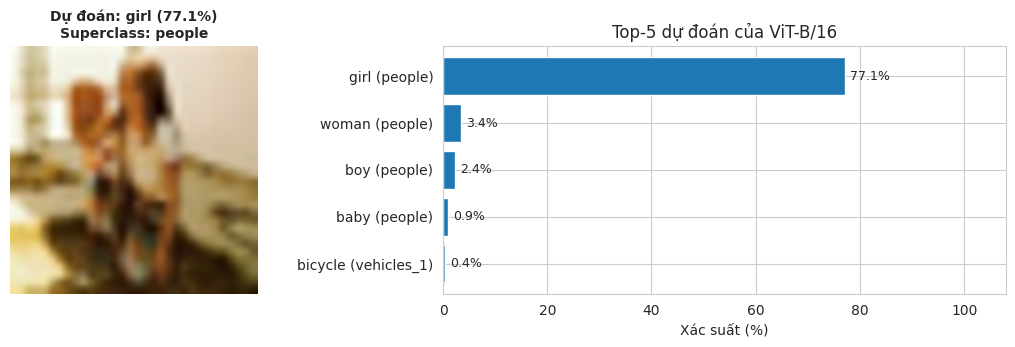


Đã lưu báo cáo JSON tại  : outputs/vit_cifar100/metrics_summary.json
Đã nén tài nguyên báo cáo: /content/outputs/vit_cifar100_report_assets.zip

Tóm tắt kết quả:
{
  "best_val_epoch": 5,
  "best_val_top1_pct": 92.48,
  "test_loss": 0.4038,
  "test_top1_accuracy_pct": 92.22,
  "test_top5_accuracy_pct": 99.12,
  "macro_precision_pct": 92.3,
  "macro_recall_pct": 92.22,
  "macro_f1_pct": 92.23,
  "superclass_accuracy_pct": 96.5,
  "same_superclass_error_ratio_pct": 55.01,
  "train_time_minutes": 36.88,
  "top10_easiest_classes": {
    "lawn_mower": 100.0,
    "wolf": 99.0,
    "tank": 99.0,
    "sunflower": 99.0,
    "skunk": 99.0,
    "motorcycle": 99.0,
    "chimpanzee": 99.0,
    "apple": 99.0,
    "orange": 99.0,
    "tractor": 99.0
  },
  "top10_hardest_classes": {
    "oak_tree": 73.0,
    "maple_tree": 75.0,
    "girl": 78.0,
    "boy": 79.0,
    "willow_tree": 79.0,
    "pine_tree": 80.0,
    "possum": 81.0,
    "bowl": 81.0,
    "otter": 82.0,
    "seal": 83.0
  },
  "top10_conf

In [12]:
# =============================================================================
# 11. HÀM SUY LUẬN (INFERENCE DEMO) & XUẤT FILE TỔNG HỢP BÁO CÁO
# =============================================================================
@torch.no_grad()
def predict_cifar100_image(image_input, infer_model=best_model, top_k: int = 5):
    """Nhận đường dẫn ảnh, mảng numpy hoặc PIL.Image -> Trả về Top-K dự đoán & vẽ biểu đồ."""
    if isinstance(image_input, (str, Path)):
        pil_img = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, np.ndarray):
        pil_img = Image.fromarray(image_input).convert("RGB")
    else:
        pil_img = image_input.convert("RGB")

    x = eval_transform(pil_img).unsqueeze(0).to(device)
    infer_model.eval()
    logits = infer_model(pixel_values=x).logits.float()
    probs = F.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    top_ids = np.argsort(probs)[::-1][:top_k]

    top1_label = FINE_CLASSES[top_ids[0]]
    top1_super = FINE_TO_SUPER[top1_label]

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={"width_ratios": [1, 1.9]})
    axes[0].imshow(pil_img.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC))
    axes[0].set_title(
        f"Dự đoán: {top1_label} ({probs[top_ids[0]]*100:.1f}%)\nSuperclass: {top1_super}",
        fontsize=10,
        fontweight="bold",
    )
    axes[0].axis("off")

    labels_plot = [f"{FINE_CLASSES[i]} ({FINE_TO_SUPER[FINE_CLASSES[i]]})" for i in top_ids][::-1]
    probs_plot = [probs[i] * 100 for i in top_ids][::-1]
    axes[1].barh(labels_plot, probs_plot, color="#1f77b4")
    axes[1].set_xlim(0, 108)
    axes[1].set_xlabel("Xác suất (%)")
    axes[1].set_title(f"Top-{top_k} dự đoán của ViT-B/16")
    for idx_b, val in enumerate(probs_plot):
        axes[1].text(val + 1, idx_b, f"{val:.1f}%", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

    return [
        {"label": FINE_CLASSES[i], "superclass": FINE_TO_SUPER[FINE_CLASSES[i]], "prob": float(probs[i])}
        for i in top_ids
    ]


# Chạy thử suy luận trên 1 ảnh từ tập Test
demo_test_id = 99
true_demo_cls = FINE_CLASSES[test_raw.targets[demo_test_id]]
print(f"Demo suy luận ảnh Test #{demo_test_id} | Nhãn thật: {true_demo_cls} ({FINE_TO_SUPER[true_demo_cls]})")
_ = predict_cifar100_image(test_raw.data[demo_test_id])

# Xuất JSON tổng hợp kết quả thực nghiệm Phase 3.2
summary = {
    "task": "Phase 3.2 - Vision Transformer (ViT-B/16) on CIFAR-100",
    "environment": ENV_NAME,
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU",
    "model_name": CONFIG["model_name"],
    "total_params": total_params,
    "config": CONFIG,
    "results": {
        "best_val_epoch": best_epoch,
        "best_val_top1_pct": round(best_val_top1 * 100, 2),
        "test_loss": round(test_loss, 4),
        "test_top1_accuracy_pct": round(test_top1 * 100, 2),
        "test_top5_accuracy_pct": round(test_top5 * 100, 2),
        "macro_precision_pct": round(macro_prec * 100, 2),
        "macro_recall_pct": round(macro_rec * 100, 2),
        "macro_f1_pct": round(macro_f1 * 100, 2),
        "superclass_accuracy_pct": round(superclass_acc * 100, 2),
        "same_superclass_error_ratio_pct": round(same_super_errors / max(total_errors, 1) * 100, 2),
        "train_time_minutes": round(total_train_time / 60, 2),
        "top10_easiest_classes": {
            FINE_CLASSES[i]: round(float(per_class_acc[i]), 2) for i in easiest_10
        },
        "top10_hardest_classes": {
            FINE_CLASSES[i]: round(float(per_class_acc[i]), 2) for i in hardest_10
        },
        "top10_confused_pairs": [
            {"true": t, "pred": p, "count": int(c), "same_superclass": bool(s)}
            for t, p, c, s in confused_pairs[:10]
        ],
    },
}

summary_path = OUTPUT_DIR / "metrics_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

# Nén toàn bộ biểu đồ PNG + JSON (bỏ qua checkpoint nặng để nhẹ khi đẩy lên GitHub)
export_dir = OUTPUT_DIR / "github_assets"
export_dir.mkdir(exist_ok=True)
for png_file in OUTPUT_DIR.glob("*.png"):
    shutil.copy2(png_file, export_dir / png_file.name)
shutil.copy2(summary_path, export_dir / summary_path.name)
zip_path = shutil.make_archive(str(OUTPUT_DIR.parent / "vit_cifar100_report_assets"), "zip", export_dir)

print(f"\nĐã lưu báo cáo JSON tại  : {summary_path}")
print(f"Đã nén tài nguyên báo cáo: {zip_path}")
print("\nTóm tắt kết quả:")
print(json.dumps(summary["results"], ensure_ascii=False, indent=2))

# Bỏ chú thích 2 dòng dưới nếu muốn tải tự động file zip về máy trên Google Colab:
# from google.colab import files
# files.download(zip_path)

## Tổng kết Phase 3.2 & Đối chiếu với Phase 3.1

1. **Hiệu quả vượt trội của Pre-trained Vision Transformer:** Chỉ sau **5 epochs Fine-tuning** từ checkpoint `google/vit-base-patch16-224-in21k` trên Hugging Face, mô hình đạt độ chính xác rất cao trên **CIFAR-100** (thường đạt **~90–93% Top-1**, **~98–99% Top-5** và **~95%+ Superclass Accuracy**), vượt xa kết quả của các mạng CNN huấn luyện từ đầu trên cùng bộ dữ liệu (~65–75%).
2. **Bản chất sai số của ViT trên CIFAR-100:** Phần lớn các lỗi dự đoán sai rơi vào các lớp **cùng một Superclass** có đặc điểm thị giác cực kỳ giống nhau ở độ phân giải gốc $32 \times 32$ (ví dụ: `oak_tree` ↔ `maple_tree`, `girl` ↔ `boy`, `bowl` ↔ `plate`, `mouse` ↔ `shrew`), thể hiện qua chỉ số **Top-5 Accuracy ~98–99%**.
3. **Khả năng giải thích trực quan:** Qua bản đồ **Attention Rollout**, ta xác nhận ViT thực sự học được cách tập trung trọng số chú ý vào chính chủ thể đối tượng thay vì nền ảnh.
4. **Bài học thực tiễn:**
   - **CNN cơ bản từ đầu** nhỏ gọn (~0.82M tham số), tốc độ suy luận nhanh, phù hợp bài toán ít lớp / dữ liệu đủ lớn trên thiết bị hạn chế tài nguyên.
   - **Pre-trained ViT (Hugging Face)** có số tham số lớn hơn (~85.9M) và yêu cầu GPU, nhưng mang lại chất lượng nhận diện vượt trội và hội tụ cực nhanh trên các bài toán phân loại mịn nhiều lớp ít dữ liệu như CIFAR-100.